## Import Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
random_state = 59
np.random.seed(random_state)
torch.manual_seed(random_state)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_state)

## Pre-Processing data

In [ ]:
from scipy.stats import qmc

class Helicopter:
    def __init__(self, data):
        self.rho = np.array(data.get('rho'))
        self.f_factor = np.array(data.get('f_factor'))
        self.weight = np.array(data.get('weight'))
        self.k_factor = np.array(data.get('k_factor'))
        self.rotor_radius = np.array(data.get('rotor_radius'))
        self.velocity = np.array(data.get("velocity"))

    def CalculateDrag(self):
        Dp = 0.5 * self.rho * self.velocity**2 * self.f_factor
        Di = (self.k_factor * self.weight**2) / (2 * self.rho * self.velocity**2 * (np.pi) * self.rotor_radius**2)
        return Dp, Di

    def FindOptimalVelocity(self, Dt):
        index_opt = np.argmin(Dt)
        v_opt = self.velocity[index_opt]
        D_min = Dt[index_opt]
        return v_opt, D_min

In [ ]:
class Sample:
    def __init__(self, design_space, n_samples):
        self.bound = design_space
        self.n_samples = n_samples
        self.labels = list(design_space.keys())
        self.lower_bound = [self.bound[key][0] for key in self.labels]
        self.upper_bound = [self.bound[key][1] for key in self.labels]

    def CreateSample(self):
        sampler = qmc.LatinHypercube(d=len(self.labels))
        sample = sampler.random(n=self.n_samples)
        scaled_sample = qmc.scale(sample, self.lower_bound, self.upper_bound)
        return pd.DataFrame(scaled_sample, columns=self.labels)

class Dataset:
    def __init__(self, sample):
        self.sample = sample

    def CreateDataset(self):
        df = self.sample.CreateSample()

        sample_obj = Helicopter(df.to_dict('list'))

        Dp, Di = sample_obj.CalculateDrag()
        df['Total_drag'] = Dp + Di
        return df

In [ ]:
design_space = {
    "rho": [1.1, 1.125],
    "f_factor": [0.2, 1.5],
    "weight": [5000, 50000],
    "k_factor": [1.1, 1.5],
    "rotor_radius": [3.5, 10],
    "velocity": [20, 200]
}

In [ ]:
sample_engine = Sample(design_space, 6000)
dataset_engine = Dataset(sample_engine)
df_dataset = dataset_engine.CreateDataset() # (6000, 7)

In [ ]:
X = df_dataset.drop('Total_drag', axis=1)   # (6000, 6)
y = df_dataset['Total_drag']    # (6000,)

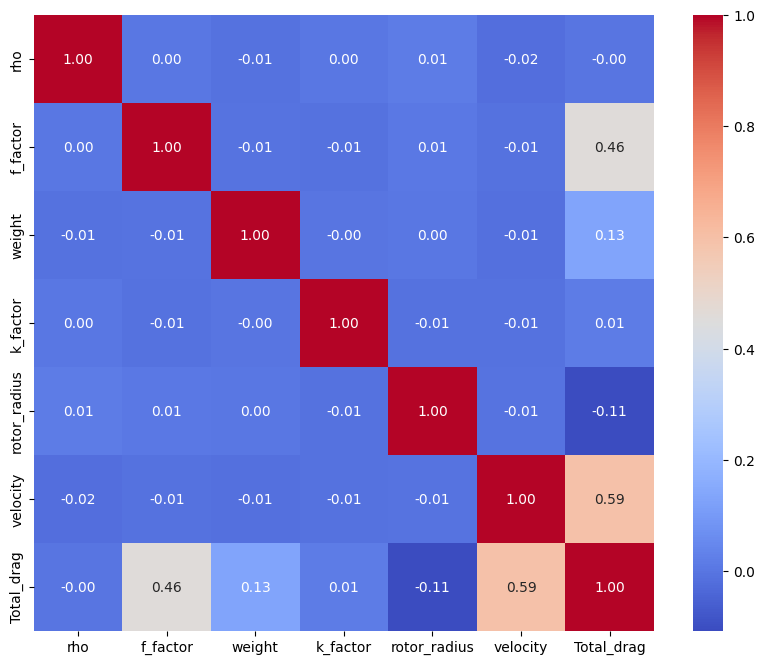

In [ ]:
# Corrolation

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    df_dataset.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.show()

## Split data

In [ ]:
from sklearn.model_selection import train_test_split

# Split Train và Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

#y_train_log = np.log1p(y_train)

# Split Validation và Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)

## Normalize data

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_X = StandardScaler()

# Features
X_train = scaler_X.fit_transform(X_train)   # (4200, 6)
X_val = scaler_X.transform(X_val)           # (900, 6)
X_test = scaler_X.transform(X_test)         # (900, 6)

In [ ]:
import torch

X_train_tensor = torch.from_numpy(X_train).float()                      # [4200, 6]
y_train_tensor = torch.from_numpy(y_train.values).float().view(-1, 1)   # [4200, 1]

X_val_tensor = torch.from_numpy(X_val).float()                      # [900, 6]
y_val_tensor = torch.from_numpy(y_val.values).float().view(-1, 1)   # [900, 1]

X_test_tensor = torch.from_numpy(X_test).float()                      # [900, 6
y_test_tensor = torch.from_numpy(y_test.values).float().view(-1, 1)   # [900, 1]

In [ ]:
print("Train:", X_train_tensor.shape, y_train_tensor.shape)
print("Val:", X_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_test_tensor.shape, y_test_tensor.shape)

Train: torch.Size([4200, 6]) torch.Size([4200, 1])
Val: torch.Size([900, 6]) torch.Size([900, 1])
Test: torch.Size([900, 6]) torch.Size([900, 1])


## Data Loader

In [ ]:
# Data Loader

class CustomDataSet(torch.utils.data.Dataset):
    def __init__(self, X_data, y_data):
        self.X_data = X_data
        self.y_data = y_data

    def __getitem__(self, index):
        return self.X_data[index], self.y_data[index]

    def __len__(self):
        return len(self.y_data)


In [ ]:
from torch.utils.data import Dataset, DataLoader

BATCH_SIZE = 32

dataset_train = CustomDataSet(X_train_tensor, y_train_tensor)
dataset_val = CustomDataSet(X_val_tensor, y_val_tensor)
dataset_test = CustomDataSet(X_test_tensor, y_test_tensor)

train_loader = DataLoader(dataset=dataset_train, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=dataset_val, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=dataset_test, batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
print(df_dataset['Total_drag'].describe())

count     6000.000000
mean      8201.944121
std       6598.788736
min        181.051834
25%       3288.932242
50%       6133.533969
75%      11337.006993
max      83520.944533
Name: Total_drag, dtype: float64


## Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()

model.fit(X_train_tensor, y_train_tensor)

y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)

print("MSE:", mean_squared_error(y_val_tensor, y_val_pred))
print("Train R2:", r2_score(y_train, y_train_pred))
print("Val R2:", r2_score(y_val, y_val_pred))

MSE: 26183463.059835188
Train R2: 0.6312223793868705
Val R2: 0.49219276358103226


## MLP network

In [ ]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_dims):
        super(MLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dims, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
input_dims = X_train_tensor.shape[1]  # the number of input feature

hidden1_dims = 1024
hidden2_dims = 512
output_dims = 1

model = MLP(input_dims=input_dims).to(device)


criterion = torch.nn.MSELoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3
)

## Training

In [ ]:
import torch
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

epochs = 100

train_losses = []
val_losses = []

train_maes = []
val_maes = []

train_rmses = []
val_rmses = []

train_r2s = []
val_r2s = []


def evaluate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_targets = []
    all_predictions = []

    with torch.no_grad():

        for X_samples, y_samples in loader:

            X_samples = X_samples.to(device)
            y_samples = y_samples.to(device).float()

            outputs = model(X_samples)

            y_samples = y_samples.reshape_as(outputs)

            loss = criterion(outputs, y_samples)

            batch_size = X_samples.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_predictions.extend(outputs.cpu().numpy().reshape(-1))
            all_targets.extend(y_samples.cpu().numpy().reshape(-1))

    avg_loss = total_loss / total_samples

    mae = mean_absolute_error(all_targets, all_predictions)

    rmse = np.sqrt(np.mean(
        (np.array(all_targets) - np.array(all_predictions)) ** 2
    ))

    r2 = r2_score(all_targets, all_predictions)

    return avg_loss, mae, rmse, r2


for epoch in range(epochs):

    # =====================================
    # 1. TRAINING
    # =====================================

    model.train()

    for X_samples, y_samples in train_loader:

        X_samples = X_samples.to(device)
        y_samples = y_samples.to(device).float()

        optimizer.zero_grad()

        outputs = model(X_samples)

        # Đảm bảo cùng shape
        y_samples = y_samples.reshape_as(outputs)

        loss = criterion(outputs, y_samples)

        loss.backward()

        optimizer.step()

    # =====================================
    # 2. EVALUATION
    # =====================================

    train_loss, train_mae, train_rmse, train_r2 = evaluate(
        model, train_loader, criterion, device
    )

    val_loss, val_mae, val_rmse, val_r2 = evaluate(
        model, val_loader, criterion, device
    )

    # =====================================
    # 3. SAVE METRICS
    # =====================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_maes.append(train_mae)
    val_maes.append(val_mae)

    train_rmses.append(train_rmse)
    val_rmses.append(val_rmse)

    train_r2s.append(train_r2)
    val_r2s.append(val_r2)

    # =====================================
    # 4. PRINT RESULTS
    # =====================================

    print(
        f"\nEPOCH {epoch + 1}:"
        f"\n\tTrain Loss: {train_loss:.4f}"
        f"\tVal Loss: {val_loss:.4f}"
        f"\n\tTrain MAE: {train_mae:.4f}"
        f"\tVal MAE: {val_mae:.4f}"
        f"\n\tTrain RMSE: {train_rmse:.4f}"
        f"\tVal RMSE: {val_rmse:.4f}"
        f"\n\tTrain R2: {train_r2:.4f}"
        f"\tVal R2: {val_r2:.4f}"
    )


EPOCH 1:
	Train Loss: 1573595.1318	Val Loss: 7226031.6806
	Train MAE: 451.6720	Val MAE: 615.1609
	Train RMSE: 1254.4302	Val RMSE: 2688.1277
	Train R2: 0.9622	Val R2: 0.8599

EPOCH 2:
	Train Loss: 1556320.7704	Val Loss: 7248800.5070
	Train MAE: 442.6821	Val MAE: 608.7310
	Train RMSE: 1247.5258	Val RMSE: 2692.3596
	Train R2: 0.9626	Val R2: 0.8594

EPOCH 3:
	Train Loss: 1546234.8486	Val Loss: 7248417.6155
	Train MAE: 436.6834	Val MAE: 602.8175
	Train RMSE: 1243.4769	Val RMSE: 2692.2886
	Train R2: 0.9629	Val R2: 0.8594

EPOCH 4:
	Train Loss: 1535279.2917	Val Loss: 7234525.1944
	Train MAE: 433.2779	Val MAE: 599.7768
	Train RMSE: 1239.0638	Val RMSE: 2689.7070
	Train R2: 0.9631	Val R2: 0.8597

EPOCH 5:
	Train Loss: 1527652.4961	Val Loss: 7240787.0724
	Train MAE: 430.9677	Val MAE: 598.2488
	Train RMSE: 1235.9824	Val RMSE: 2690.8711
	Train R2: 0.9633	Val R2: 0.8596

EPOCH 6:
	Train Loss: 1520086.8311	Val Loss: 7235058.9007
	Train MAE: 427.1016	Val MAE: 595.8324
	Train RMSE: 1232.9180	Val RMSE:

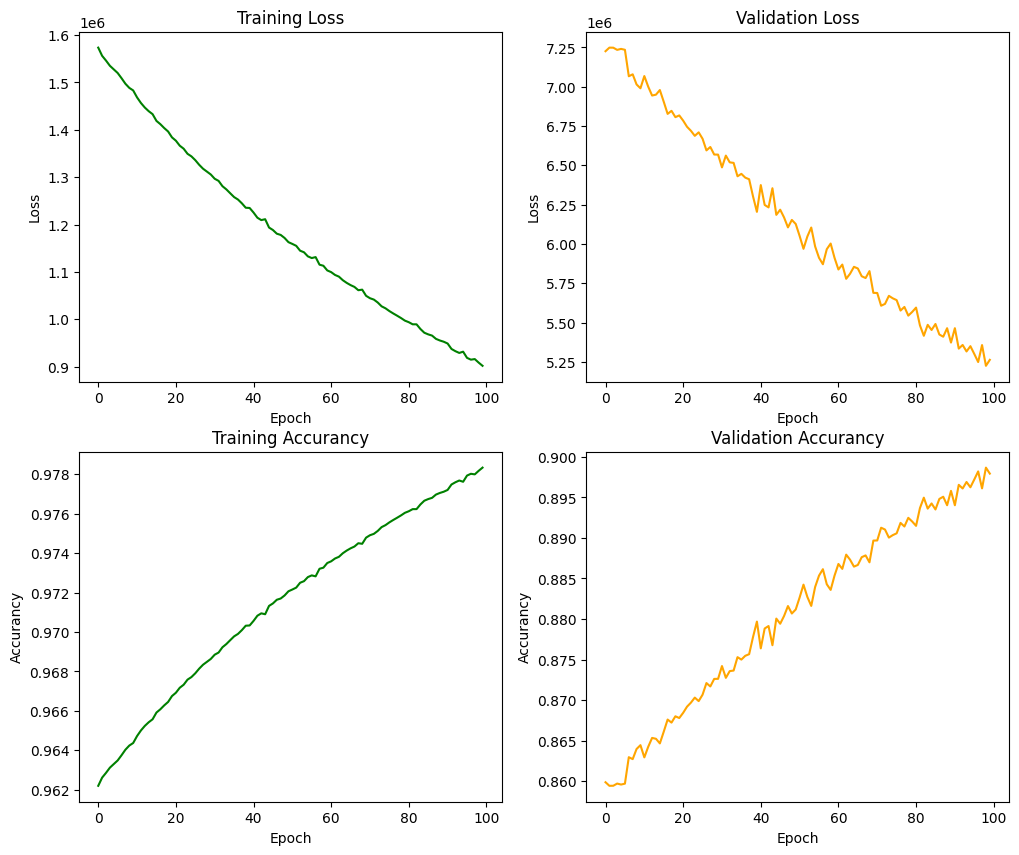

In [ ]:
# Plot for average session

# Convert GPU tensors in metric lists to standard CPU float values for plotting
train_accurancy_plot = [r.cpu().item() if isinstance(r, torch.Tensor) else r for r in train_r2s]
val_accurancy_plot = [r.cpu().item() if isinstance(r, torch.Tensor) else r for r in val_r2s]

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].plot(train_losses, color='green')
ax[0, 0].set(xlabel='Epoch', ylabel='Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color='orange')
ax[0, 1].set(xlabel='Epoch', ylabel='Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_accurancy_plot, color='green')
ax[1, 0].set(xlabel='Epoch', ylabel='Accurancy')
ax[1, 0].set_title('Training Accurancy')

ax[1, 1].plot(val_accurancy_plot, color='orange')
ax[1, 1].set(xlabel='Epoch', ylabel='Accurancy')
ax[1, 1].set_title('Validation Accurancy')

plt.show()


## Testing

In [ ]:
# Find best model

best_epoch = np.argmin(val_losses)

print("Best epoch:", best_epoch + 1)
print("Best Val Loss:", val_losses[best_epoch])

Best epoch: 99
Best Val Loss: 5224482.936458333


In [ ]:
# Save model

import os

# Create the models directory if it does not exist
os.makedirs("models", exist_ok=True)

torch.save({
        'epoch': best_epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_loss': val_losses[best_epoch]
    }, "models/best_model.pth")

In [ ]:
# Load model

checkpoint = torch.load(
    "models/best_model.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

print(f"Loaded epoch: {checkpoint['epoch']}")
print(f"Best Val Loss: {checkpoint['val_loss']:.4f}")

Loaded epoch: 98
Best Val Loss: 5224482.9365


In [ ]:
y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        y_true.extend(y_batch.cpu().numpy().flatten())
        y_pred.extend(outputs.cpu().numpy().flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual shape:", y_true.shape)
print("Predicted shape:", y_pred.shape)

Actual shape: (900,)
Predicted shape: (900,)


In [ ]:
test_mse = mean_squared_error(y_true, y_pred)
test_mae = mean_absolute_error(y_true, y_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_true, y_pred)

print("========== TEST RESULTS ==========")
print(f"Test MSE:  {test_mse:.4f}")
print(f"Test MAE:  {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R2:   {test_r2:.4f}")

========== TEST RESULTS ==========
Test MSE:  1462387.8750
Test MAE:  358.5437
Test RMSE: 1209.2923
Test R2:   0.9670
